# Compiling Python

## When there is no library function

Notebook 04 showed the best strategy: let a compiled library such as BLAS do the work. But sometimes the computation you need is not available as a ready-made array operation: a custom simulation, an unusual algorithm, a loop with complicated conditions. Then you have to write the loop yourself.

Three tools let you keep writing (almost) Python and still get compiled speed. They differ in *when* and *how* the compilation happens:

| Tool | Strategy | Changes to your code |
|---|---|---|
| **Numba** | JIT: compiles individual functions while the program runs | Add a decorator |
| **Cython** | AOT: translates Python-like code to C before the program runs | Add type declarations |
| **PyPy** | JIT for the whole interpreter | None |

As a test we use, once again, the three-loop matrix multiplication, and compare with C from notebook 03.

In [ ]:
import numpy as np

from compare_efficiency.benchmark import gflops, random_matrices, time_function

matrix_a, matrix_b = random_matrices(256)
reference_result = matrix_a @ matrix_b

## Numba: a just-in-time compiler for functions

**Numba** compiles individual Python functions to machine code. You mark a function with the `@njit` **decorator** (a line starting with `@` placed above a function, which modifies how the function behaves).

The first time the function is called, Numba looks at the types of the arguments it receives (for example, "two 2D arrays of float64"), compiles a machine-code version specialised for exactly those types, and stores it. Every later call with the same types runs the compiled version directly. The compiling is done by **LLVM**, the same compiler technology behind Clang (a C compiler), Rust and Julia.

The limitation: Numba only understands part of Python, mainly numbers, NumPy arrays, loops and simple functions. It cannot compile code that uses arbitrary objects, pandas tables or most other libraries.

This is the textbook `ijk` version, identical to the pure Python code apart from the decorator:

In [ ]:
from numba import njit

@njit
def matmul_numba_ijk(matrix_a: np.ndarray, matrix_b: np.ndarray) -> np.ndarray:
    n = matrix_a.shape[0]
    result = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            total = 0.0
            for k in range(n):
                total += matrix_a[i, k] * matrix_b[k, j]
            result[i, j] = total
    return result

The first call includes the compilation, so it is much slower than the following ones:

In [ ]:
import time

start = time.perf_counter()
numba_result = matmul_numba_ijk(matrix_a, matrix_b)
first_call_seconds = time.perf_counter() - start
second_call_seconds = time_function(lambda: matmul_numba_ijk(matrix_a, matrix_b), warmup=0, repeats=1)

f"first call: {first_call_seconds:.3f} s, second call: {second_call_seconds:.4f} s"

'first call: 0.186 s, second call: 0.0148 s'

In [ ]:
np.allclose(numba_result, reference_result)

True

And the cache-friendly `ikj` order from notebook 03:

In [ ]:
@njit
def matmul_numba_ikj(matrix_a: np.ndarray, matrix_b: np.ndarray) -> np.ndarray:
    n = matrix_a.shape[0]
    result = np.zeros((n, n))
    for i in range(n):
        for k in range(n):
            a_ik = matrix_a[i, k]
            for j in range(n):
                result[i, j] += a_ik * matrix_b[k, j]
    return result

np.allclose(matmul_numba_ikj(matrix_a, matrix_b), reference_result)

True

In [ ]:
numba_seconds = {
    "Numba ijk": time_function(lambda: matmul_numba_ijk(matrix_a, matrix_b), repeats=3),
    "Numba ikj": time_function(lambda: matmul_numba_ikj(matrix_a, matrix_b), repeats=3),
}
{name: f"{gflops(256, seconds):.1f} GFLOPS" for name, seconds in numba_seconds.items()}

{'Numba ijk': '2.3 GFLOPS', 'Numba ikj': '38.5 GFLOPS'}

The C versions from notebook 03, on the same matrices:

In [ ]:
from compare_efficiency.c_library import call_c_matmul, compile_c_library, load_c_library

c_library = load_c_library(compile_c_library(["-O3", "-march=native"], "O3"))
c_seconds = {
    "C ijk": time_function(lambda: call_c_matmul(c_library.matmul_ijk, matrix_a, matrix_b), repeats=3),
    "C ikj": time_function(lambda: call_c_matmul(c_library.matmul_ikj, matrix_a, matrix_b), repeats=3),
}
{name: f"{gflops(256, seconds):.1f} GFLOPS" for name, seconds in c_seconds.items()}

{'C ijk': '2.4 GFLOPS', 'C ikj': '34.2 GFLOPS'}

Numba reaches roughly the speed of C for the same loop, because both end up as similar machine code. The loop-order lesson from notebook 03 still applies: compiling does not fix a poor memory-access pattern. And neither Numba nor C comes close to BLAS (notebook 04), because they compile *our* simple algorithm, not a cache-blocked one.

## Cython: Python with C types, compiled ahead of time

**Cython** is a language that extends Python with C types. A Cython file is translated into C, and the C is compiled into an **extension module**: a compiled file that Python imports like any other module. Parts of scikit-learn, pandas and SciPy are written this way. It needs a C compiler installed.

In a notebook, the `%%cython` line at the top of a cell compiles that cell on the spot. It must be enabled once with `%load_ext Cython`:

In [ ]:
%load_ext Cython

First, our pure Python function compiled unchanged. Plain Python is valid Cython, but every value is still a boxed Python object (the deep dive [Numbers and memory](numbers_and_memory.ipynb)), so there is little to gain. (The function has no type hints on purpose: Cython uses annotations such as `float` as C types, which would turn it into a typed version.)

In [ ]:
%%cython
def matmul_cython_untyped(matrix_a, matrix_b):
    n = len(matrix_a)
    result = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            total = 0.0
            for k in range(n):
                total += matrix_a[i][k] * matrix_b[k][j]
            result[i][j] = total
    return result

Now a version with C types, which is where Cython's speed comes from:

- `double[:, ::1]` declares that the argument is a 2D block of `double` values stored row by row (a **typed memoryview**). Cython can then read the NumPy array's memory directly, with no boxes.
- `cdef` declares C variables: `Py_ssize_t` is a C integer for indices, `double` a C decimal number.
- The two `@cython....(False)` lines switch off the safety checks on indices (out-of-range and negative indices), as in C. The code gets faster, but a wrong index would silently read the wrong memory instead of raising an error.
- `--compile-args` passes the same optimisation flags we gave to `gcc` in notebook 03.

In [ ]:
%%cython --compile-args=-O3 --compile-args=-march=native
import numpy as np
cimport cython

@cython.boundscheck(False)
@cython.wraparound(False)
def matmul_cython_typed(double[:, ::1] matrix_a, double[:, ::1] matrix_b):
    cdef Py_ssize_t n = matrix_a.shape[0]
    cdef Py_ssize_t i, j, k
    cdef double a_ik
    result = np.zeros((n, n))
    cdef double[:, ::1] result_view = result
    for i in range(n):
        for k in range(n):
            a_ik = matrix_a[i, k]
            for j in range(n):
                result_view[i, j] += a_ik * matrix_b[k, j]
    return result

In [ ]:
list_a, list_b = matrix_a.tolist(), matrix_b.tolist()
{
    "Cython untyped": np.allclose(matmul_cython_untyped(list_a, list_b), reference_result),
    "Cython typed": np.allclose(matmul_cython_typed(matrix_a, matrix_b), reference_result),
}

{'Cython untyped': True, 'Cython typed': True}

In [ ]:
cython_seconds = {
    "Cython untyped": time_function(lambda: matmul_cython_untyped(list_a, list_b), repeats=3),
    "Cython typed": time_function(lambda: matmul_cython_typed(matrix_a, matrix_b), repeats=3),
}
{name: f"{gflops(256, seconds):.2f} GFLOPS" for name, seconds in cython_seconds.items()}

{'Cython untyped': '0.17 GFLOPS', 'Cython typed': '36.08 GFLOPS'}

Compiling without types gives only a small gain: the interpreter's instruction-by-instruction work disappears, but the boxes and the type checks remain. Once the types are declared, Cython generates the same loop a C programmer would write, and it runs at C speed.

## PyPy: a faster Python interpreter

Python is a language; **CPython** is only its standard implementation (notebook 01). **PyPy** is an alternative implementation with a built-in JIT compiler. While the program runs, it detects the loops that run most often, records the operations and types it actually sees, and compiles that path to machine code. Inside those compiled loops it can even avoid boxing numbers. It needs **no changes to the code**.

`scripts/pypy_benchmark.py` times the unchanged `matmul_pure_python` function from notebook 03. The `uv` tool downloads PyPy automatically and runs the script outside this project's environment (`--no-project`), because PyPy follows CPython's versions with some delay. We run the same script with this notebook's CPython for comparison. Each run prints its results in **JSON**, a standard text format for data, which `json.loads` converts into a Python dictionary.

In [ ]:
import json
import shutil
import subprocess
import sys

from compare_efficiency.project_paths import SCRIPTS_DIRECTORY

def run_pure_python_benchmark(command: list[str]) -> dict:
    completed = subprocess.run(command, capture_output=True, text=True, check=True)
    return json.loads(completed.stdout)

pypy_run = run_pure_python_benchmark(
    [shutil.which("uv"), "run", "--no-project", "--python", "pypy@3.11", str(SCRIPTS_DIRECTORY / "pypy_benchmark.py")])
cpython_run = run_pure_python_benchmark([sys.executable, str(SCRIPTS_DIRECTORY / "pypy_benchmark.py")])

{f"{run['implementation']} {run['version']}": {n: f"{float(seconds) * 1000:.1f} ms" for n, seconds in run["seconds"].items()}
 for run in (cpython_run, pypy_run)}

{'CPython 3.14.4': {'64': '5.0 ms', '128': '38.2 ms', '256': '322.2 ms'},
 'PyPy 3.11.13': {'64': '0.4 ms', '128': '2.9 ms', '256': '21.4 ms'}}

In [ ]:
{n: f"PyPy is {float(cpython_run['seconds'][n]) / float(pypy_run['seconds'][n]):.0f}x faster"
 for n in cpython_run["seconds"]}

{'64': 'PyPy is 13x faster',
 '128': 'PyPy is 13x faster',
 '256': 'PyPy is 15x faster'}

A large speed-up with zero effort. So why is PyPy not used for AI? Because of the ecosystem:

- The AI libraries (NumPy, PyTorch, TensorFlow…) are **C extensions** built for CPython's internals. PyPy can only imitate those internals, through a compatibility layer that is slow and incomplete. PyTorch does not support PyPy at all.
- NumPy code already spends its time inside compiled libraries, so a faster interpreter has almost nothing left to speed up.
- PyPy lags behind CPython's versions (3.11 here, while CPython is at 3.14).

The lesson goes beyond PyPy: **a language, or an implementation of it, is chosen for its ecosystem as much as for its speed.**

## Comparing every approach

All the implementations at $n = 256$. The scale is logarithmic: each gridline is ten times faster than the previous one. NumPy is included for reference, limited to one thread like all the others (notebook 04).

In [ ]:
from threadpoolctl import threadpool_limits

with threadpool_limits(limits=1):
    numpy_seconds = time_function(lambda: matrix_a @ matrix_b)
comparison = {
    "pure CPython": gflops(256, float(cpython_run["seconds"]["256"])),
    "Cython untyped": gflops(256, cython_seconds["Cython untyped"]),
    "PyPy": gflops(256, float(pypy_run["seconds"]["256"])),
    "Numba ijk": gflops(256, numba_seconds["Numba ijk"]),
    "C ijk": gflops(256, c_seconds["C ijk"]),
    "Cython typed": gflops(256, cython_seconds["Cython typed"]),
    "Numba ikj": gflops(256, numba_seconds["Numba ikj"]),
    "C ikj": gflops(256, c_seconds["C ikj"]),
    "NumPy (BLAS), 1 thread": gflops(256, numpy_seconds),
}

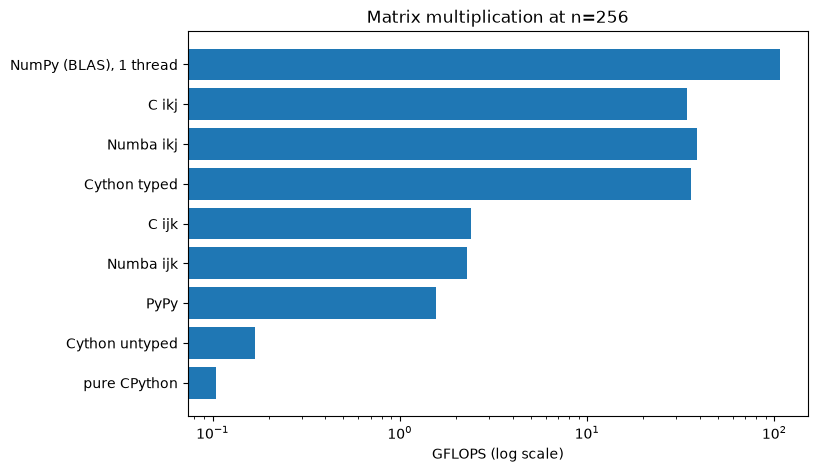

In [ ]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(8, 5))
axis.barh(list(comparison), list(comparison.values()))
axis.set_xscale("log")
axis.set_xlabel("GFLOPS (log scale)")
axis.set_title("Matrix multiplication at n=256")
plt.show()

| Tool | How it gets its speed | Code changes | Main cost |
|---|---|---|---|
| NumPy (BLAS) | Calls tuned compiled libraries | Rewrite loops as array operations | Only for operations the library provides |
| Numba | JIT-compiles functions through LLVM | A decorator and simple loops | Supports only part of Python; compile time on the first call |
| Cython | AOT translation to C | Type declarations | Needs a C compiler and a build step |
| PyPy | JIT for the whole interpreter | None | Poor compatibility with the C extensions of the AI stack |

In practice, AI code relies on the first row almost everywhere, and reaches for Numba or Cython only for the occasional custom loop.

## Seeing where Cython still uses Python

`%%cython --annotate` produces a report of the generated code. Yellow lines still interact with Python objects (slow); white lines are pure C. Click a line to see the C code generated for it. The untyped version is almost entirely yellow:

In [ ]:
%%cython --annotate
def matmul_cython_untyped_annotated(matrix_a, matrix_b):
    n = len(matrix_a)
    result = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            total = 0.0
            for k in range(n):
                total += matrix_a[i][k] * matrix_b[k][j]
            result[i][j] = total
    return result

In the typed version, the three loops are white:

In [ ]:
%%cython --annotate --compile-args=-O3 --compile-args=-march=native
import numpy as np
cimport cython

@cython.boundscheck(False)
@cython.wraparound(False)
def matmul_cython_typed_annotated(double[:, ::1] matrix_a, double[:, ::1] matrix_b):
    cdef Py_ssize_t n = matrix_a.shape[0]
    cdef Py_ssize_t i, j, k
    cdef double a_ik
    result = np.zeros((n, n))
    cdef double[:, ::1] result_view = result
    for i in range(n):
        for k in range(n):
            a_ik = matrix_a[i, k]
            for j in range(n):
                result_view[i, j] += a_ik * matrix_b[k, j]
    return result

## Parallel loops with Numba

Numba can also split a loop across threads (see the deep dive [Inside BLAS](inside_blas.ipynb)). Replacing `range` with `prange` in the outer loop, and adding `parallel=True`, tells Numba that the iterations are independent. Here they are: each `i` writes a different row of the result, so no two threads ever write to the same place.

In [ ]:
from numba import prange

@njit(parallel=True)
def matmul_numba_ikj_parallel(matrix_a: np.ndarray, matrix_b: np.ndarray) -> np.ndarray:
    n = matrix_a.shape[0]
    result = np.zeros((n, n))
    for i in prange(n):
        for k in range(n):
            a_ik = matrix_a[i, k]
            for j in range(n):
                result[i, j] += a_ik * matrix_b[k, j]
    return result

np.allclose(matmul_numba_ikj_parallel(matrix_a, matrix_b), reference_result)

True

In [ ]:
parallel_comparison = {}
for n in (256, 1024):
    matrix_a_n, matrix_b_n = random_matrices(n)
    serial_seconds = time_function(lambda: matmul_numba_ikj(matrix_a_n, matrix_b_n), repeats=3)
    parallel_seconds = time_function(lambda: matmul_numba_ikj_parallel(matrix_a_n, matrix_b_n), repeats=3)
    parallel_comparison[n] = {"serial": f"{gflops(n, serial_seconds):.1f} GFLOPS",
                              "parallel": f"{gflops(n, parallel_seconds):.1f} GFLOPS"}
parallel_comparison

{256: {'serial': '38.7 GFLOPS', 'parallel': '2.6 GFLOPS'},
 1024: {'serial': '36.9 GFLOPS', 'parallel': '103.0 GFLOPS'}}

The same lesson as NumPy's threads in the deep dive [Inside BLAS](inside_blas.ipynb): starting and coordinating threads has a fixed cost. At $n = 256$ the work is too small to pay for it, and the parallel version can even be slower; at $n = 1024$ it pays off.

## Key ideas

- When no library function fits, Python code can still be compiled: **Numba** (JIT, per function), **Cython** (AOT, with type declarations) or **PyPy** (a JIT interpreter).
- Compiled Python reaches roughly the speed of C for the same loop, but not the speed of BLAS.
- The speed comes from knowing the types in advance and removing boxes, not from the Python syntax itself.
- PyPy shows that raw speed is not enough: compatibility with the ecosystem decides what is used.